Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


# =====================================================================
# 1. LOAD + CLEAN
# =====================================================================

In [2]:
df = pd.read_csv("Retail_Inventory_Dataset", parse_dates=["date"])
print("Raw shape:", df.shape)

Raw shape: (50060, 19)


In [3]:
df.head()

,date,product_id,product_name,category,day_of_week,month,is_weekend,is_holiday,lag_7,lag_14,rolling_mean_7,rolling_mean_30,price,promotion_flag,current_stock,reorder_level,lead_time_days,units_sold,next_7d_demand
0,2024-05-31,P001,Basmati Rice 5kg,Grocery,4,5,0,0,104.0,54.0,67.43,72.17,249.13,1,810.0,509,5,76,507.0
1,2024-06-01,P001,Basmati Rice 5kg,Grocery,5,6,1,0,64.0,94.0,63.43,72.23,239.69,1,734.0,509,5,182,469.0
2,2024-06-02,P001,Basmati Rice 5kg,Grocery,6,6,1,0,111.0,129.0,80.29,76.23,285.42,0,552.0,509,5,36,347.0
3,2024-06-03,P001,Basmati Rice 5kg,Grocery,0,6,0,0,38.0,60.0,69.57,74.47,286.83,0,516.0,509,5,59,404.0
4,2024-06-04,P001,Basmati Rice 5kg,Grocery,1,6,0,0,36.0,53.0,72.57,71.23,283.53,0,457.0,509,5,56,402.0


In [4]:
df.tail()

,date,product_id,product_name,category,day_of_week,month,is_weekend,is_holiday,lag_7,lag_14,rolling_mean_7,rolling_mean_30,price,promotion_flag,current_stock,reorder_level,lead_time_days,units_sold,next_7d_demand
50055,2025-10-08,P100,Wafers 75g,Snacks,2,10,0,0,71.0,36.0,92.29,74.30,65.35,0,193.0,320,3,48,NaN
50056,2025-10-09,P100,Wafers 75g,Snacks,3,10,0,0,132.0,74.0,89.00,72.90,64.78,0,145.0,320,3,58,NaN
50057,2025-10-10,P100,Wafers 75g,Snacks,4,10,0,0,103.0,33.0,78.43,73.53,51.93,1,1010.0,320,3,78,NaN
50058,2025-10-11,P100,Wafers 75g,Snacks,5,10,1,0,154.0,110.0,74.86,73.10,64.91,0,932.0,320,3,96,NaN
50059,2025-10-12,P100,Wafers 75g,Snacks,6,10,1,0,50.0,99.0,66.57,74.37,50.62,1,836.0,320,3,107,NaN


In [5]:
df.isnull().sum()

date                 0
product_id           0
product_name         0
category             0
day_of_week          0
month                0
is_weekend           0
is_holiday           0
lag_7                0
lag_14               0
rolling_mean_7       0
rolling_mean_30      0
price              250
promotion_flag       0
current_stock      151
reorder_level        0
lead_time_days       0
units_sold           0
next_7d_demand     601
dtype: int64

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50060 entries, 0 to 50059
Data columns (total 19 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   date             50060 non-null  datetime64[ns]
 1   product_id       50060 non-null  object        
 2   product_name     50060 non-null  object        
 3   category         50060 non-null  object        
 4   day_of_week      50060 non-null  int64         
 5   month            50060 non-null  int64         
 6   is_weekend       50060 non-null  int64         
 7   is_holiday       50060 non-null  int64         
 8   lag_7            50060 non-null  float64       
 9   lag_14           50060 non-null  float64       
 10  rolling_mean_7   50060 non-null  float64       
 11  rolling_mean_30  50060 non-null  float64       
 12  price            49810 non-null  float64       
 13  promotion_flag   50060 non-null  int64         
 14  current_stock    49909 non-null  float

In [7]:
df.duplicated().sum()

np.int64(60)

In [8]:
df = df.drop_duplicates(subset=["date", "product_id"]).sort_values(["product_id", "date"]).reset_index(drop=True)

In [9]:
# missing values: forward-fill inside each product, then product median as fallback
for col in ["price", "current_stock"]:
    df[col] = df.groupby("product_id")[col].transform(lambda s: s.ffill().bfill())

In [10]:
df.isnull().sum()

date                 0
product_id           0
product_name         0
category             0
day_of_week          0
month                0
is_weekend           0
is_holiday           0
lag_7                0
lag_14               0
rolling_mean_7       0
rolling_mean_30      0
price                0
promotion_flag       0
current_stock        0
reorder_level        0
lead_time_days       0
units_sold           0
next_7d_demand     600
dtype: int64

In [11]:
df = df.dropna(subset=['next_7d_demand'])

# =====================================================================
# 2. FEATURE ENGINEERING
# =====================================================================

In [12]:
# Sort chronologically for each product
df = df.sort_values(["product_id", "date"]).reset_index(drop=True)

# Group by product
g = df.groupby("product_id")["units_sold"]

# Lag features
df["lag_7"] = g.shift(7)
df["lag_14"] = g.shift(14)

# Rolling features
df["rolling_mean_7"] = g.transform(
    lambda s: s.shift(1).rolling(7).mean()
)

df["rolling_mean_30"] = g.transform(
    lambda s: s.shift(1).rolling(30).mean()
)

# Remove rows where historical features aren't available
df = df.dropna(
    subset=[
        "lag_7",
        "lag_14",
        "rolling_mean_7",
        "rolling_mean_30"
    ]
).reset_index(drop=True)

print("Shape after cleaning + feature rebuild:", df.shape)

Shape after cleaning + feature rebuild: (46400, 19)


====Important Insights About Dataset====

1. 46,400 total rows
2. 100 unique products
3. 464 rows per product
4. Every product has exactly 464 observations

In [13]:
print(df.shape)
print(df["product_id"].nunique())


(46400, 19)
100


In [14]:
print(
    df[["product_id", "product_name", "category"]]
    .drop_duplicates()
    .sort_values("product_id")
    .head(20)
)

     product_id             product_name       category
0          P001         Basmati Rice 5kg        Grocery
464        P002       Full Cream Milk 1L          Dairy
928        P003                  Cola 2L      Beverages
1392       P004        Potato Chips 100g         Snacks
1856       P005         Bath Soap 4-Pack  Personal Care
2320       P006     Detergent Powder 2kg      Household
2784       P007   Frozen Green Peas 500g   Frozen Foods
3248       P008        Notebook A4 200pg     Stationery
3712       P009  Wheat Flour (Atta) 10kg        Grocery
4176       P010            Toned Milk 1L          Dairy
4640       P011          Orange Juice 1L      Beverages
5104       P012      Salted Peanuts 200g         Snacks
5568       P013            Shampoo 340ml  Personal Care
6032       P014    Dishwash Liquid 750ml      Household
6496       P015        French Fries 750g   Frozen Foods
6960       P016         Ball Pen 10-Pack     Stationery
7424       P017             Toor Dal 1kg        

In [15]:
df.duplicated().sum()
df.isnull().sum()

date               0
product_id         0
product_name       0
category           0
day_of_week        0
month              0
is_weekend         0
is_holiday         0
lag_7              0
lag_14             0
rolling_mean_7     0
rolling_mean_30    0
price              0
promotion_flag     0
current_stock      0
reorder_level      0
lead_time_days     0
units_sold         0
next_7d_demand     0
dtype: int64

=== Data is cleaned and contains ZERO Duplicate and Null Values ====

========== Data Visualization =========

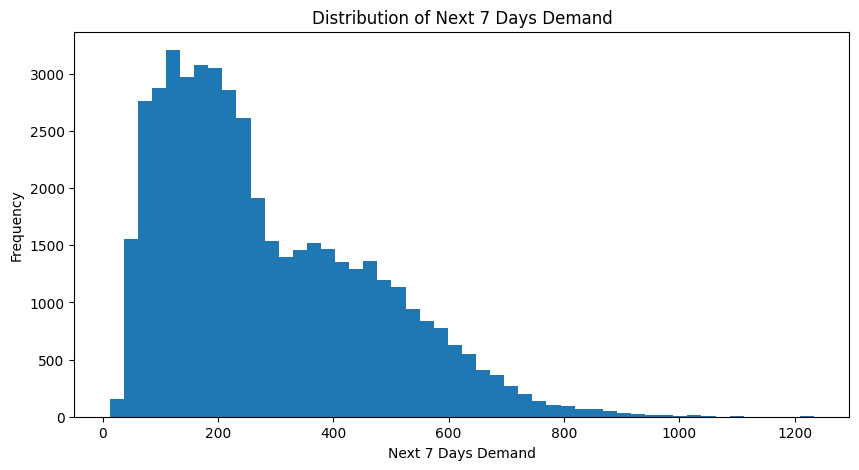

In [16]:
# 1. Distribution of the target

plt.figure(figsize=(10, 5))
plt.hist(df['next_7d_demand'], bins=50)
plt.xlabel('Next 7 Days Demand')
plt.ylabel('Frequency')
plt.title('Distribution of Next 7 Days Demand')
plt.show()

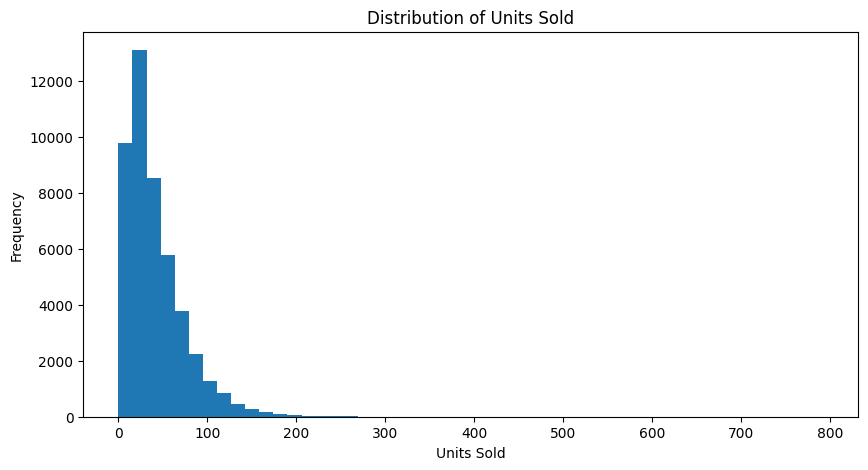

In [17]:
# 2. Distribution of units_sold
# (This helps us understand the historical sales behavior.)
plt.figure(figsize=(10, 5))
plt.hist(df['units_sold'], bins=50)
plt.xlabel('Units Sold')
plt.ylabel('Frequency')
plt.title('Distribution of Units Sold')
plt.show()

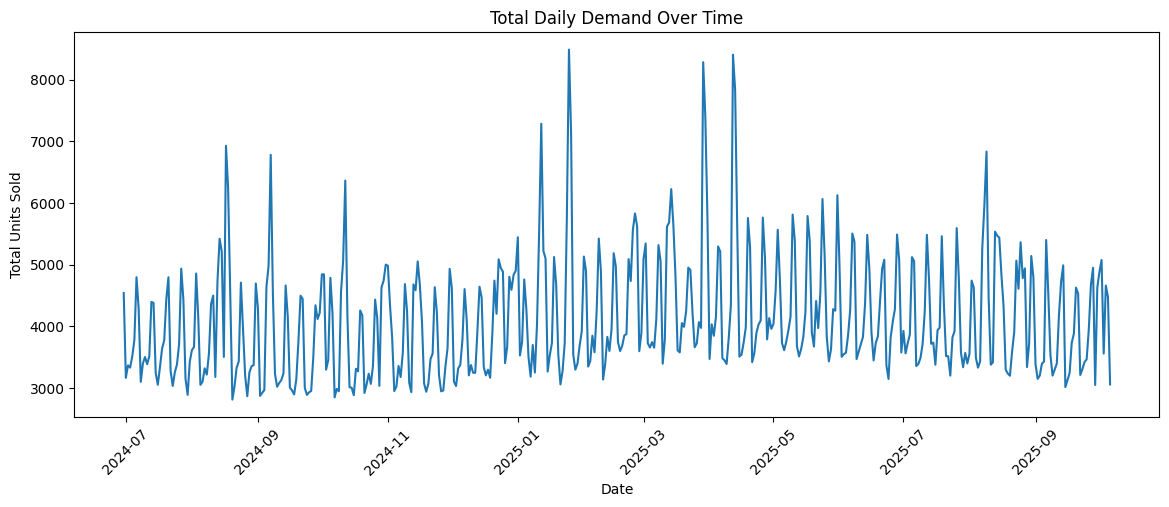

In [18]:
# 3. Demand Over Time
# This can reveal trends, peaks, drops, and seasonality.

daily_demand = df.groupby('date')['units_sold'].sum()

plt.figure(figsize=(14, 5))
plt.plot(daily_demand)
plt.xlabel('Date')
plt.ylabel('Total Units Sold')
plt.title('Total Daily Demand Over Time')
plt.xticks(rotation=45)
plt.show()

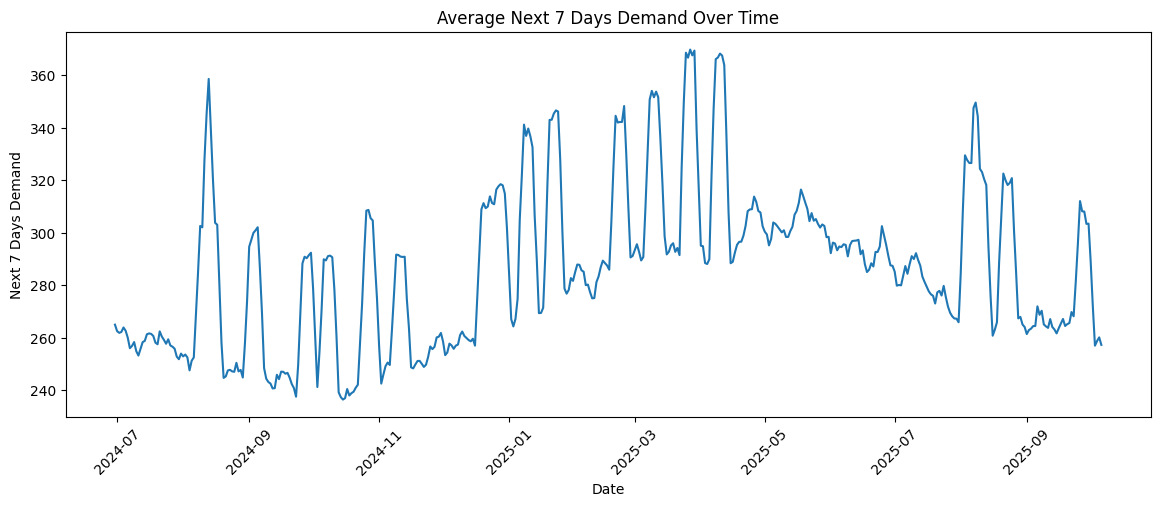

In [19]:
daily_target = df.groupby('date')['next_7d_demand'].mean()

plt.figure(figsize=(14, 5))
plt.plot(daily_target)
plt.xlabel('Date')
plt.ylabel('Next 7 Days Demand')
plt.title('Average Next 7 Days Demand Over Time')
plt.xticks(rotation=45)
plt.show()

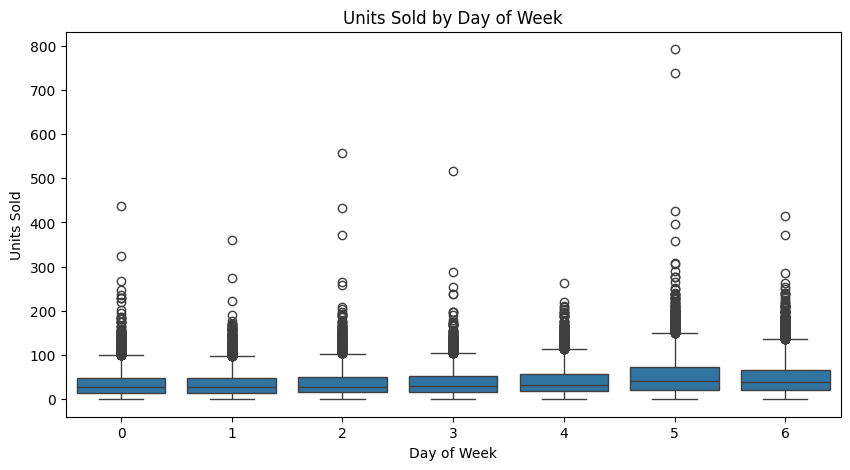

In [20]:
# 4. Demand by day of week

plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x='day_of_week', y='units_sold')
plt.xlabel('Day of Week')
plt.ylabel('Units Sold')
plt.title('Units Sold by Day of Week')
plt.show()

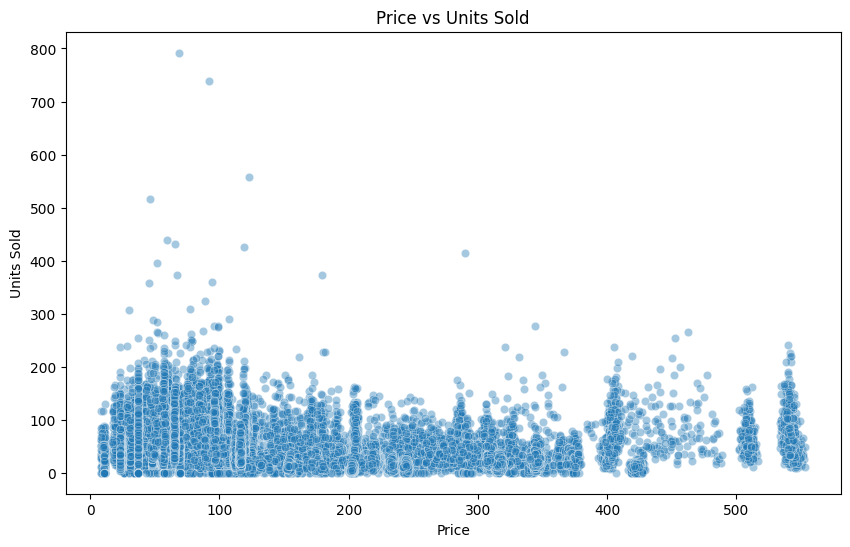

In [21]:
# Price Vs units sold

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df,
    x='price',
    y='units_sold',
    alpha=0.4
)

plt.xlabel('Price')
plt.ylabel('Units Sold')
plt.title('Price vs Units Sold')
plt.show()

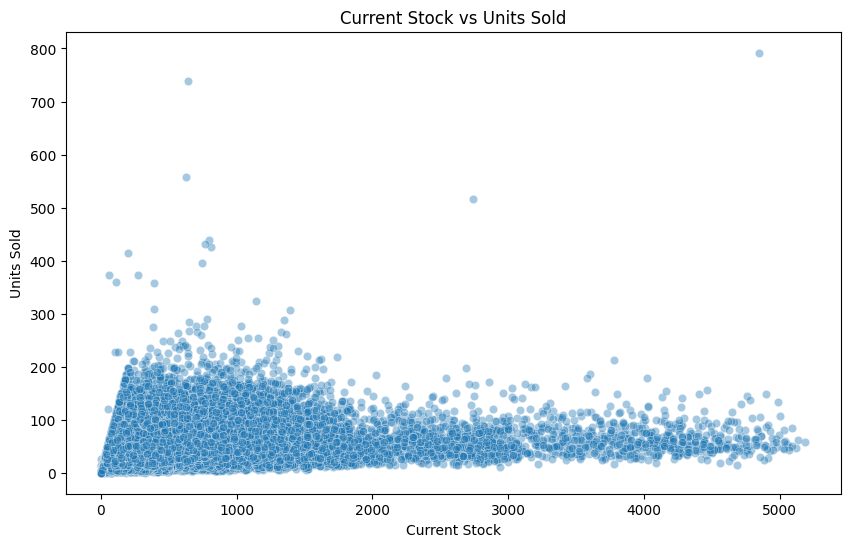

In [22]:
# 5. Current stock vs units sold

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df,
    x='current_stock',
    y='units_sold',
    alpha=0.4
)

plt.xlabel('Current Stock')
plt.ylabel('Units Sold')
plt.title('Current Stock vs Units Sold')
plt.show()

The Top 10 products by total sales:

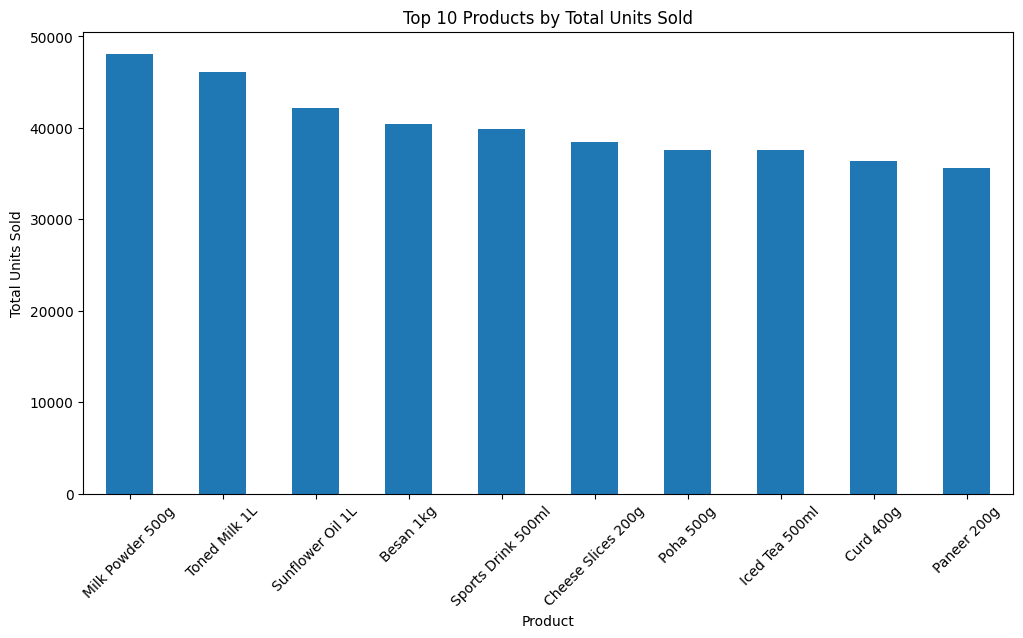

In [24]:
top_products = (
    df.groupby('product_name')['units_sold']
      .sum()
      .sort_values(ascending=False)
      .head(10)
)

plt.figure(figsize=(12, 6))
top_products.plot(kind='bar')

plt.xlabel('Product')
plt.ylabel('Total Units Sold')
plt.title('Top 10 Products by Total Units Sold')
plt.xticks(rotation=45)
plt.show()

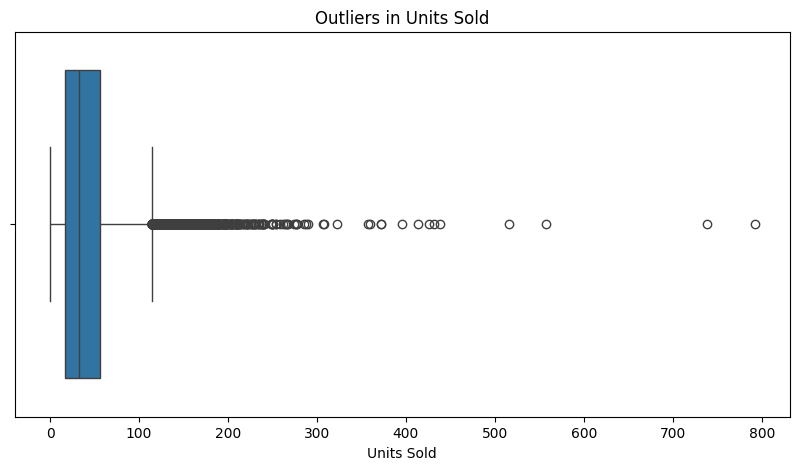

In [25]:
plt.figure(figsize=(10, 5))
sns.boxplot(x=df['units_sold'])

plt.title('Outliers in Units Sold')
plt.xlabel('Units Sold')
plt.show()

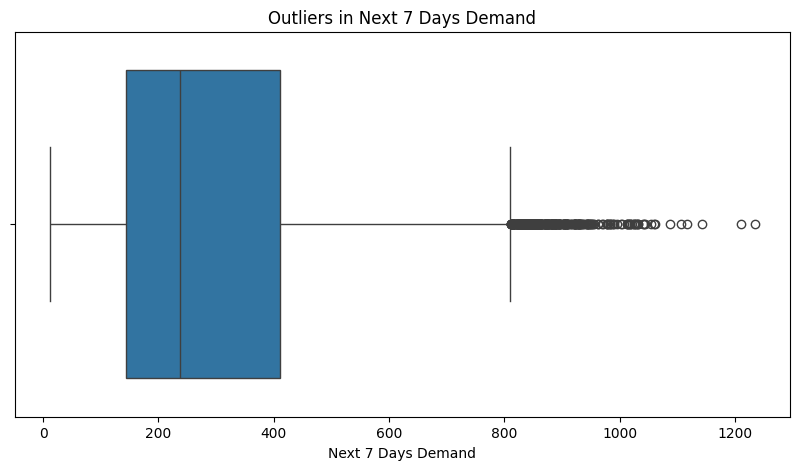

In [26]:
plt.figure(figsize=(10, 5))
sns.boxplot(x=df['next_7d_demand'])

plt.title('Outliers in Next 7 Days Demand')
plt.xlabel('Next 7 Days Demand')
plt.show()

=================== Feature Selection =====================

In [27]:
# Correlation with target
numeric_cols = df.select_dtypes(include=["int64", "float64"]).columns

correlation = (
    df[numeric_cols]
    .corr()["next_7d_demand"]
    .sort_values(ascending=False)
)

print(correlation)

next_7d_demand     1.000000
rolling_mean_30    0.939161
rolling_mean_7     0.889281
units_sold         0.763344
lag_14             0.701996
lag_7              0.697546
reorder_level      0.632210
current_stock      0.404822
is_holiday         0.042550
promotion_flag     0.021776
day_of_week        0.000019
is_weekend        -0.000255
lead_time_days    -0.048902
month             -0.080642
price             -0.200935
Name: next_7d_demand, dtype: float64


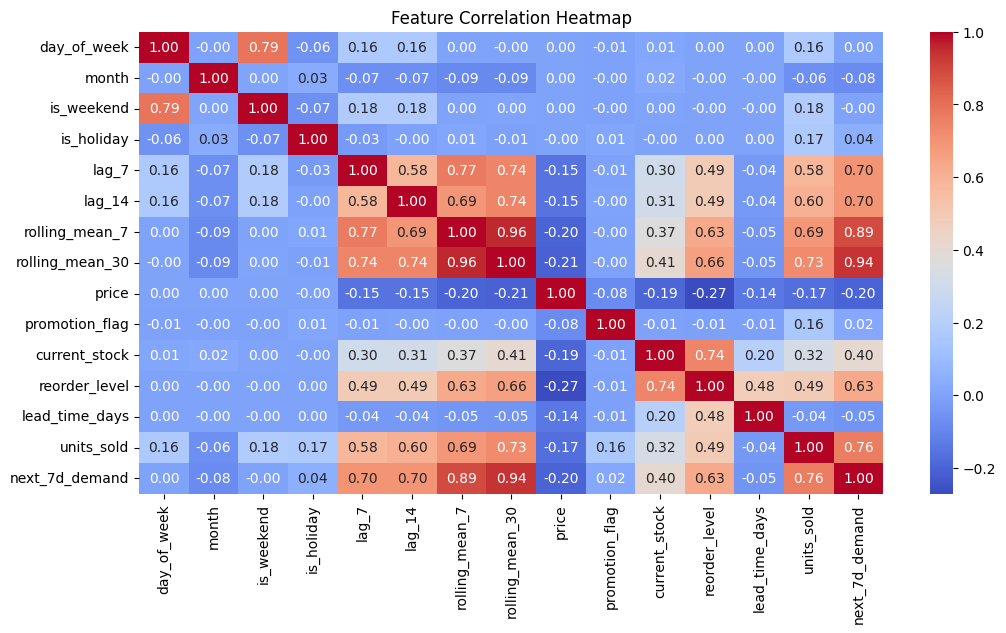

In [30]:
plt.figure(figsize=(12, 6))

sns.heatmap(
    df[numeric_cols].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Feature Correlation Heatmap")
plt.show()

In [37]:
features = [
    "day_of_week",
    "month",
    "is_weekend",
    "is_holiday",
    "lag_7",
    "lag_14",
    "rolling_mean_7",
    "rolling_mean_30",
    "price",
    "promotion_flag",
    "current_stock",
    "reorder_level",
    "lead_time_days",
    "units_sold"
]

X = df[features]
y = df["next_7d_demand"]

In [38]:
print("X shape:", X.shape)
print("y shape:", y.shape)


X shape: (46400, 14)
y shape: (46400,)


In [39]:
df = df.sort_values(["date", "product_id"]).reset_index(drop=True)

80% for training and 20% for testing:

In [40]:
split_index = int(len(df) * 0.8)

train_df = df.iloc[:split_index]
test_df = df.iloc[split_index:]

print("Train:", train_df.shape)
print("Test:", test_df.shape)

print("Train dates:", train_df["date"].min(), "to", train_df["date"].max())
print("Test dates:", test_df["date"].min(), "to", test_df["date"].max())

Train: (37120, 19)
Test: (9280, 19)
Train dates: 2024-06-30 00:00:00 to 2025-07-06 00:00:00
Test dates: 2025-07-06 00:00:00 to 2025-10-06 00:00:00


In [41]:
X_train = train_df[features]
y_train = train_df["next_7d_demand"]

X_test = test_df[features]
y_test = test_df["next_7d_demand"]


print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (37120, 14)
y_train: (37120,)
X_test: (9280, 14)
y_test: (9280,)


================ Model Selection and Training Process Start ==================

In [59]:
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


xgb_model = XGBRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_train, y_train)

y_pred_xgb = xgb_model.predict(X_test)

mae_xgb = mean_absolute_error(y_test, y_pred_xgb)
rmse_xgb = np.sqrt(mean_squared_error(y_test, y_pred_xgb))
r2_xgb = r2_score(y_test, y_pred_xgb)

print("XGBoost Results")
print("MAE :", mae_xgb)
print("RMSE:", rmse_xgb)
print("R²  :", r2_xgb)

XGBoost Results
MAE : 37.757581050231536
RMSE: 54.67698730151588
R²  : 0.9103707475670366


========= Testing Of Model Predictions ============

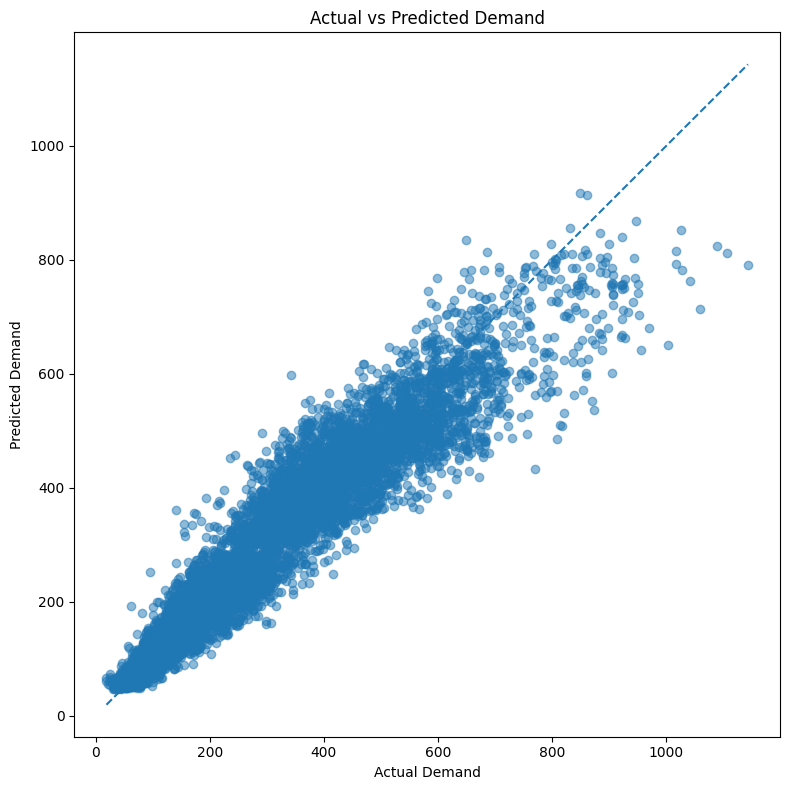

In [65]:
plt.figure(figsize=(8, 8))

plt.scatter(
    y_test,
    y_pred_xgb,
    alpha=0.5
)

# Perfect prediction line
min_val = min(y_test.min(), y_pred_xgb.min())
max_val = max(y_test.max(), y_pred_xgb.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    linestyle="--"
)

plt.xlabel("Actual Demand")
plt.ylabel("Predicted Demand")
plt.title("Actual vs Predicted Demand")

plt.tight_layout()
plt.show()

=========== Save the final model =============

In [69]:
import joblib

joblib.dump(xgb_model, "xgboost_demand_model.pkl")

print("Model saved successfully!")

Model saved successfully!


========== Save the feature list =============
This ensures that your dashboard uses the same 14 features in the same expected structure.


In [70]:
joblib.dump(features, "model_features.pkl")

print(features)

['day_of_week', 'month', 'is_weekend', 'is_holiday', 'lag_7', 'lag_14', 'rolling_mean_7', 'rolling_mean_30', 'price', 'promotion_flag', 'current_stock', 'reorder_level', 'lead_time_days', 'units_sold']
